# $K_p, K_d$ Constants Analysis — 추가 분석 제안 및 수행

`K_constants_analysis.ipynb`의 ToDo를 이어가기 위한 보완 분석입니다.

| ToDo (원본 노트북) | 이 노트북의 대응 섹션 |
|---|---|
| 실제 Loss 기반 최적 $K_p, K_d$ 계산 수식 도출 및 최적값 계산 | §1 기존 분석 점검, §2 목표 G 재정의, §3 pooled 회귀 |
| 실제 Loss 기반 최적 $K_p, K_d$ 변화 양상 파악 | §4 expanding-window 추정 |
| PAPE 기반 $\hat G, G$ 계산 | §3, §5 (의사결정 관점 평가) |
| PAPE 기반과 실제 Loss 기반 차이 모델링 | §6 PAPE 오차 모델링 |
| PAPE 값 보정 방안 도출 | §7 라벨 지연 하 온라인 보정, §8 보정 후 의사결정 품질 |

**데이터**: APIGraph 2015 validation 12개월. `keep` = 2014-12까지 학습 후 고정된 모델, `retrain` = 매월 직전 달까지 재학습한 모델, PAPE = keep 모델의 라벨 없는 loss 추정치(uniform / DRE, seed 11·23·37).

> ⚠️ 표본이 **결정 시점 10개**뿐이므로 아래 모든 수치는 "방향성 확인"용입니다. 결론을 확정하려면 2016–2018 test 구간 또는 주 단위 granularity로 표본을 늘려야 합니다 (§9).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [2]:
keep = pd.read_csv('keep_monthly.csv', encoding='utf-8-sig')
ret = pd.read_csv('retrain_monthly.csv', encoding='utf-8-sig')
cm = pd.read_csv('./pape/validation/confusion_matrix.csv', encoding='utf-8-sig')
pe = pd.read_csv('./pape/validation/pape_estimates.csv', encoding='utf-8-sig')
pe['month'] = pe['target_chunk_id'].str.extract(r'monthly:(\d{4}-\d{2})', expand=False)

print('confusion_matrix rows:', len(cm))
cm.groupby(['input_variant', 'observed_month']).size().unstack(0).head(4)

confusion_matrix rows: 72


input_variant,all_binary__dre,all_binary__uniform
observed_month,,
2015-01,3,3
2015-02,3,3
2015-03,3,3
2015-04,3,3


## §1. 기존 노트북 점검 (분석 전에 먼저 수정해야 할 부분)

### 1-1. PAPE 행 인덱싱 오류 — 가장 중요
`confusion_matrix.csv`는 **월마다 seed 3개(11, 23, 37)** 의 행이 있습니다. 원본 노트북은 `input_variant`로만 필터링한 뒤 `uniform_pape['estimated_loss'][i]`로 접근하므로, 인덱스 `i`가 월 `i`가 아니라 **월 `i // 3`** 을 가리킵니다. 즉 원본의 `kp_pape_*`, `kd_pape_*`, `FN_uni/FN_dre`, 상관 heatmap은 대부분 엉뚱한 달의 PAPE 값과 실제 loss를 섞어서 계산되었습니다.

In [3]:
uniform_pape_orig = cm[cm['input_variant'] == 'all_binary__uniform'].reset_index()  # 원본 노트북 방식
check = pd.DataFrame({
    'keep_loss row i (month)': keep['month'],
    'uniform_pape[i] 가 실제로 가리키는 month': uniform_pape_orig['observed_month'][:len(keep)].values,
    'seed': uniform_pape_orig['seed'][:len(keep)].values,
})
check

,keep_loss row i (month),uniform_pape[i] 가 실제로 가리키는 month,seed
0,2015-01,2015-01,11
1,2015-02,2015-01,23
2,2015-03,2015-01,37
3,2015-04,2015-02,11
4,2015-05,2015-02,23
5,2015-06,2015-02,37
6,2015-07,2015-03,11
7,2015-08,2015-03,23
8,2015-09,2015-03,37
9,2015-10,2015-04,11


**수정**: (input_variant, month) 단위로 seed를 평균(또는 seed 하나 선택)한 뒤 `month`를 key로 merge 합니다. seed 간 표준편차는 PAPE 추정의 불확실성 지표로 따로 보관합니다 (uniform은 seed 간 차이가 0, DRE는 최대 ±16).

In [4]:
agg = (cm.groupby(['input_variant', 'observed_month'])
         .agg(est_loss=('estimated_loss', 'mean'), est_loss_sd=('estimated_loss', 'std'),
              est_fn=('estimated_fn', 'mean'), est_fp=('estimated_fp', 'mean'),
              act_loss=('actual_loss', 'first'), act_fn=('actual_fn', 'first'), act_fp=('actual_fp', 'first'),
              n=('n_target', 'first'))
         .reset_index())
diag = (pe[pe['input_variant'] == 'all_binary__dre']
          .groupby('month')[['dre_auc', 'ess_ratio', 'max_weight']].mean())

df = pd.DataFrame({'month': keep['month'], 'n': keep['n_apps'],
                   'keep_cnt': keep['loss'], 'ret_cnt': ret['loss']}).set_index('month')
for v, name in [('all_binary__uniform', 'uni'), ('all_binary__dre', 'dre')]:
    a = agg[agg['input_variant'] == v].set_index('observed_month')
    assert (a['act_loss'] == df['keep_cnt']).all(), 'PAPE actual_loss != keep loss'
    df[f'{name}_cnt'] = a['est_loss']
    df[f'{name}_sd'] = a['est_loss_sd'] / a['n']
    df[f'{name}_fn'] = a['est_fn']; df[f'{name}_fp'] = a['est_fp']
df['act_fn'] = keep.set_index('month')['FN']; df['act_fp'] = keep.set_index('month')['FP']
df = df.join(diag)

# 앱 수로 정규화한 loss rate (2015-08은 앱 수가 3111로 다른 달의 63% 수준)
for c in ['keep', 'ret', 'uni', 'dre']:
    df[c] = df[f'{c}_cnt'] / df['n']
df[['n', 'keep', 'ret', 'uni', 'dre', 'uni_sd', 'dre_sd', 'dre_auc', 'ess_ratio', 'max_weight']].round(4)

,n,keep,ret,uni,dre,uni_sd,dre_sd,dre_auc,ess_ratio,max_weight
month,,,,,,,,,,
2015-01,4931,0.0418,0.0195,0.0388,0.0391,0.0,0.0003,0.7304,0.3284,20.0
2015-02,4954,0.0373,0.0095,0.0403,0.0390,0.0,0.0007,0.7421,0.3121,20.0
2015-03,4939,0.0470,0.0069,0.0482,0.0465,0.0,0.0004,0.7900,0.2572,20.0
2015-04,4946,0.0354,0.0087,0.0401,0.0372,0.0,0.0003,0.8045,0.2389,20.0
2015-05,4934,0.0334,0.0085,0.0363,0.0348,0.0,0.0007,0.8067,0.2211,20.0
2015-06,4946,0.0412,0.0162,0.0400,0.0415,0.0,0.0019,0.7949,0.2402,20.0
2015-07,4824,0.0493,0.0097,0.0461,0.0471,0.0,0.0008,0.8243,0.2119,20.0
2015-08,3111,0.0485,0.0087,0.0441,0.0451,0.0,0.0010,0.8607,0.1437,20.0
2015-09,4959,0.0603,0.0105,0.0591,0.0595,0.0,0.0007,0.8285,0.2247,20.0


### 1-2. 그 밖의 점검 사항
| # | 위치 | 내용 | 영향 |
|---|---|---|---|
| a | cell 24 | `keep_loss['FP_uni'] = uniform_pape['estimated_fn']` — FP 자리에 FN을 넣음 | uni 상관 heatmap의 FP 행/열 무효 |
| b | cell 27 | `endfix = ['', '_uni', 'dre']` (언더스코어 누락, 미사용) | 영향 없음, 정리 대상 |
| c | cell 8 | `min(keep_loss['loss'][:i-1])` 는 `i-2`까지의 min → $\min_{s\le t}$와 off-by-one | P항이 음수가 나와 $K_p$가 ±로 튐 (−11, −16, −20 …) |
| d | cell 2 | $K_p P = loss_{keep}$, $K_d D = loss_{retrain}$ 분해는 G = keep − retrain 과 **부호가 맞지 않고**(두 번째 식은 $-loss_{retrain}$이어야 함), 1개 식에 미지수 2개를 임의로 나눈 것이라 식별 불가 | 월별 "최적 K"가 분모 0 근처에서 폭주 (cell 21에서 ylim(−10,10)으로 잘라야 했던 원인) |
| e | 전체 | loss를 오분류 **개수**로 사용 → 2015-08(앱 3111개)처럼 표본 크기가 다른 달은 loss가 인위적으로 작아짐 | `loss_per_app`(rate) 사용 권장 |
| f | 시간축 | RCCDA의 G(t)는 "**t 시점에 재학습했을 때 t+1에서 얻는 이득**"인데, 원본은 같은 달의 keep/retrain을 섞고 PAPE는 t−1, actual은 t를 사용 | §2에서 시간축을 명시적으로 정렬 |

**제안**: 월별로 $K$를 "역산"하는 대신, 여러 결정 시점을 모아 $G_t \approx K_p P_t + K_d D_t$를 **회귀로 추정**(§3)하고, 시간 변화는 expanding window로 본다(§4).

## §2. 목표 G의 시간축 재정의

월말 $t$에 재학습 여부를 결정한다고 하면:

- **실제 이득** $G_t = f_{keep}(t+1) - f_{retrain}(t+1)$ : `retrain_monthly`의 month $t+1$ 행은 "$t$까지 학습한 모델"이므로 정확히 "$t$에 재학습"한 결과
- **RCCDA 추정 특징** (결정 시점에 관측 가능한 deployed 모델 loss $f$ 사용)
  - $P_t = f_t - \min_{s \le t} f_s$ (원 논문 정의)
  - $D_t = f_t - f_{t-1}$
- $\hat G_t = K_p P_t + K_d D_t$, 업데이트 조건 $V \hat G_t \ge \lambda Q(t) + \tfrac12(\lambda^2 - 2\bar\lambda\lambda)$

결정 가능 시점: $D$는 $t \ge$ 2015-02, $G$는 $t \le$ 2015-11 → **결정 시점 10개**.

주의: 여기서 $f$는 "한 번도 재학습하지 않은 keep 모델" 궤적입니다. 실제 RCCDA 운영에서는 재학습 후 모델이 바뀌므로 $f$, $\min f$, PAPE 대상 모델이 모두 달라집니다 (§9의 loss matrix 제안 참고).

decision months: ['2015-02', '2015-03', '2015-04', '2015-05', '2015-06', '2015-07', '2015-08', '2015-09', '2015-10', '2015-11']


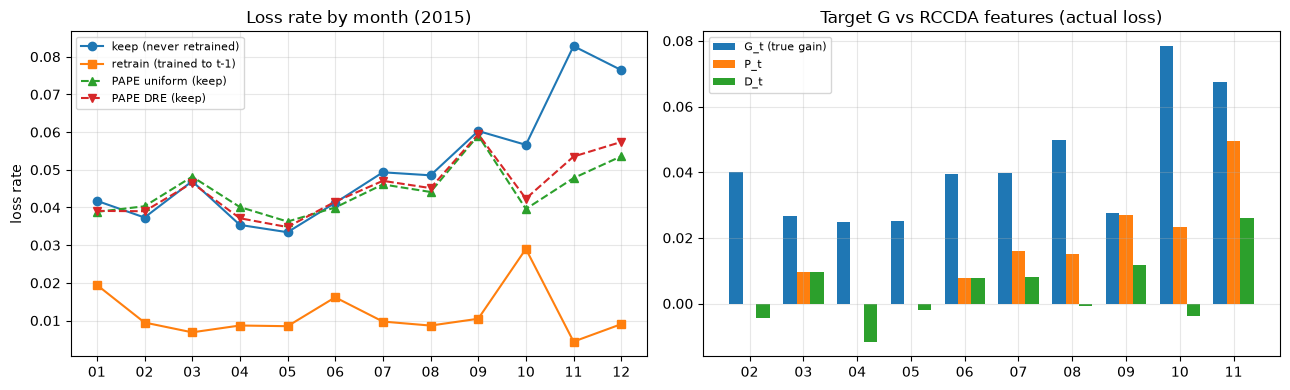

,keep,ret,G,P,D
month,,,,,
2015-02,0.0373,0.0095,0.0401,0.0000,-0.0044
2015-03,0.0470,0.0069,0.0267,0.0096,0.0096
2015-04,0.0354,0.0087,0.0249,0.0000,-0.0116
2015-05,0.0334,0.0085,0.0251,0.0000,-0.0019
2015-06,0.0412,0.0162,0.0396,0.0078,0.0078
2015-07,0.0493,0.0097,0.0399,0.0159,0.0081
2015-08,0.0485,0.0087,0.0498,0.0151,-0.0008
2015-09,0.0603,0.0105,0.0276,0.0269,0.0118
2015-10,0.0566,0.0290,0.0784,0.0232,-0.0037


In [5]:
df['G'] = (df['keep'] - df['ret']).shift(-1)   # G_t: t에서 재학습했을 때 t+1의 이득

def rccda_features(f, ref=None):
    '''f: deployed 모델 loss rate 시계열. ref가 주어지면 P의 기준점을 ref로 사용.'''
    P = f - (f.cummin() if ref is None else ref)
    D = f.diff()
    return P, D

df['P'], df['D'] = rccda_features(df['keep'])
dec = df.dropna(subset=['G', 'D']).copy()   # 결정 시점 10개
print('decision months:', list(dec.index))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = range(len(df))
ax[0].plot(x, df['keep'], 'o-', label='keep (never retrained)')
ax[0].plot(x, df['ret'], 's-', label='retrain (trained to t-1)')
ax[0].plot(x, df['uni'], '^--', label='PAPE uniform (keep)')
ax[0].plot(x, df['dre'], 'v--', label='PAPE DRE (keep)')
ax[0].set_xticks(list(x)); ax[0].set_xticklabels(df.index.str[5:]); ax[0].set_ylabel('loss rate'); ax[0].legend(fontsize=8)
ax[0].set_title('Loss rate by month (2015)')
xd = range(len(dec))
ax[1].bar([i - 0.25 for i in xd], dec['G'], 0.25, label='G_t (true gain)')
ax[1].bar(list(xd), dec['P'], 0.25, label='P_t')
ax[1].bar([i + 0.25 for i in xd], dec['D'], 0.25, label='D_t')
ax[1].set_xticks(list(xd)); ax[1].set_xticklabels(dec.index.str[5:]); ax[1].legend(fontsize=8)
ax[1].set_title('Target G vs RCCDA features (actual loss)')
plt.tight_layout(); plt.show()
dec[['keep', 'ret', 'G', 'P', 'D']].round(4)

**관찰**: $G_t$는 0.025–0.078로 항상 양수이고, $P_t, D_t$(대부분 ±0.01 수준)보다 한 자릿수 큽니다. keep 모델은 2014년 이후 한 번도 갱신되지 않아서 **"재학습만 하면 얻는 기본 이득"(≈ keep − 0.01)이 늘 깔려 있기** 때문입니다. 그런데 $P_t$의 기준점 $\min f$는 *keep 모델 자신의* 최저 loss(≈0.033)이지, 재학습으로 도달 가능한 수준(≈0.009)이 아닙니다. → RCCDA 원형 $\hat G$(절편 없음)로는 이 기본 이득을 설명할 수 없습니다. §3에서 정량 확인합니다.

## §3. Pooled 회귀로 $K_p, K_d$ 추정 (식별 가능한 방식)

월별 역산 대신 10개 결정 시점을 모아 최소제곱으로 추정합니다. 비교 대상:

| 모델 | 식 | 의미 |
|---|---|---|
| `P,D` | $K_p P + K_d D$ | RCCDA 원형 (절편 없음) |
| `P,D+c` | $K_p P + K_d D + c$ | 기본 이득 절편 추가 |
| `Pref,D` | $K_p (f_t - \min_{s\le t} f^{ret}_s) + K_d D$ | P의 기준점을 **재학습으로 도달 가능한 loss**로 교체 |
| `f only` | $K f_t$ | 현재 loss 수준만 사용 |

평가 지표: in-sample $R^2$, **LOO MAE**(leave-one-out, 과적합 확인), Spearman(순위 일치), **cap@3**(예산상 3번만 재학습할 때 $\hat G$ 상위 3개월을 고르면 실제 G 상위 3개월 이득의 몇 %를 얻는가).

$f$ 소스는 actual(keep, 라벨 즉시 도착 가정), PAPE uniform, PAPE DRE 세 가지입니다.

In [6]:
def ls_fit(X, y, intercept=False):
    A = np.c_[X, np.ones(len(X))] if intercept else X
    k = np.linalg.lstsq(A, y, rcond=None)[0]
    pred = A @ k
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return k, pred, r2

def loo_pred(X, y, intercept=False):
    out = np.empty(len(y))
    for i in range(len(y)):
        m = np.arange(len(y)) != i
        k, _, _ = ls_fit(X[m], y[m], intercept)
        out[i] = (np.r_[X[i], 1] if intercept else X[i]) @ k
    return out

def capture(score, G, k=3):
    '''예산 k회: score 상위 k개월을 골랐을 때 얻은 G / oracle 상위 k개월 G'''
    score, G = np.asarray(score), np.asarray(G)
    return G[np.argsort(-score)[:k]].sum() / G[np.argsort(-G)[:k]].sum()

def build_X(f):
    P, D = rccda_features(f)
    Pref, _ = rccda_features(f, ref=df['ret'].cummin())
    return pd.DataFrame({'P': P, 'D': D, 'Pref': Pref, 'f': f, 'G': df['G']}).dropna()

specs = [('P,D', ['P', 'D'], False), ('P,D+c', ['P', 'D'], True),
         ('Pref,D', ['Pref', 'D'], False), ('f only', ['f'], False)]
rows = []
for src in ['keep', 'uni', 'dre']:
    X = build_X(df[src]); y = X['G'].values
    for name, cols, ic in specs:
        k, pred, r2 = ls_fit(X[cols].values, y, ic)
        lp = loo_pred(X[cols].values, y, ic)
        rows.append({'f source': src, 'model': name,
                     'Kp/K': k[0], 'Kd': k[1] if len(cols) > 1 else np.nan, 'c': k[-1] if ic else np.nan,
                     'R2': r2, 'LOO_MAE': np.abs(lp - y).mean(),
                     'spearman': stats.spearmanr(pred, y)[0], 'cap@3': capture(pred, y)})
res3 = pd.DataFrame(rows)
G_dec = build_X(df['keep'])['G'].values
print(f'random policy 기대 cap@3 = {3 * G_dec.mean() / np.sort(G_dec)[-3:].sum():.2f},  '
      f'항상 0을 예측할 때 MAE = {np.abs(G_dec).mean():.4f},  평균 예측 MAE = {np.abs(G_dec - G_dec.mean()).mean():.4f}')
res3.round(3)

random policy 기대 cap@3 = 0.64,  항상 0을 예측할 때 MAE = 0.0419,  평균 예측 MAE = 0.0140


,f source,model,Kp/K,Kd,c,R2,LOO_MAE,spearman,cap@3
0,keep,"P,D",2.786,-2.355,NaN,-0.257,0.020,0.564,0.886
1,keep,"P,D+c",1.462,-1.263,0.026,0.611,0.013,0.564,0.886
2,keep,"Pref,D",1.098,-0.914,NaN,0.552,0.013,0.527,0.886
3,keep,f only,0.848,NaN,NaN,0.392,0.011,0.648,0.886
4,uni,"P,D",4.806,-3.077,NaN,-0.829,0.026,0.285,0.797
5,uni,"P,D+c",1.412,-1.488,0.033,0.306,0.022,0.139,0.783
6,uni,"Pref,D",1.161,-1.381,NaN,0.292,0.017,0.055,0.783
7,uni,f only,0.924,NaN,NaN,-0.193,0.017,0.030,0.622
8,dre,"P,D",4.033,-2.639,NaN,-0.560,0.022,0.479,0.797
9,dre,"P,D+c",1.694,-1.535,0.029,0.430,0.018,0.418,0.797


**해석**

1. **RCCDA 원형(`P,D`, 절편 없음)은 actual loss로도 $R^2<0$** — "평균값 예측"보다 못합니다. 절편 하나만 넣어도 $R^2$가 0.6 수준으로 올라가며, 절편 $c\approx0.026$이 곧 "재학습 기본 이득"입니다. → $K_p, K_d$만 맞추는 것으로는 $G$의 **크기(scale)** 를 재현할 수 없고, 기준점(min)의 정의를 바꾸거나(`Pref`) 절편/바이어스 항을 RCCDA 식에 추가하는 것이 필요합니다.
2. **$K_d$ 부호가 모든 설정에서 음수**입니다 (actual −2.4, uniform −3.1, DRE −2.6). 이 데이터에서는 "이번 달 loss가 튀면 다음 달 재학습 이득은 오히려 작다"(월 단위 노이즈의 평균 회귀)는 뜻이며, 논문이 가정하는 $K_d>0$과 반대입니다. 부록 bootstrap에서도 $P(K_d<0)\approx0.98$. 표본 10개라 확정은 못 하지만, $K_d$ 탐색 범위를 음수까지 열어 두어야 합니다.
3. 순위(Spearman, cap@3)는 actual 기준 0.56 / 0.89로 random(cap@3 기대값 0.64)보다 낫습니다. **"전 구간을 PAPE로" 대체하면 uniform은 순위 정보가 거의 사라지고**(Spearman 0.03–0.29), DRE(0.24–0.48)가 uniform보다 일관되게 낫습니다. (라벨이 도착한 과거 구간을 actual로 바꾼 현실적 혼합 구성은 §7)
4. `f only`(현재 loss 수준 하나)가 actual 기준 LOO MAE·Spearman 모두 최상 — 표본 10개에서는 단순한 모델이 이깁니다. 절편 모델은 in-sample $R^2$는 높지만 LOO 이득은 작습니다.

### 3-1. 의사결정에는 $(K_p, K_d)$의 "방향"만 중요하다

RCCDA는 $V\hat G_t$를 threshold와 비교하므로 $K$의 **크기**는 $V$와 상쇄되고(=$V$ 튜닝과 동치), 예산 제약 하에서 "어느 달을 고를지"는 $\hat G$의 **순위**, 즉 $K_d/K_p$ 비율(각도 $\phi=\mathrm{atan2}(K_d, K_p)$)에 의해서만 결정됩니다. 그래서 $(K_p, K_d)$ 2차원 탐색을 **각도 1차원 탐색 + $V$(또는 스케일) 1차원 탐색**으로 분리할 수 있습니다.

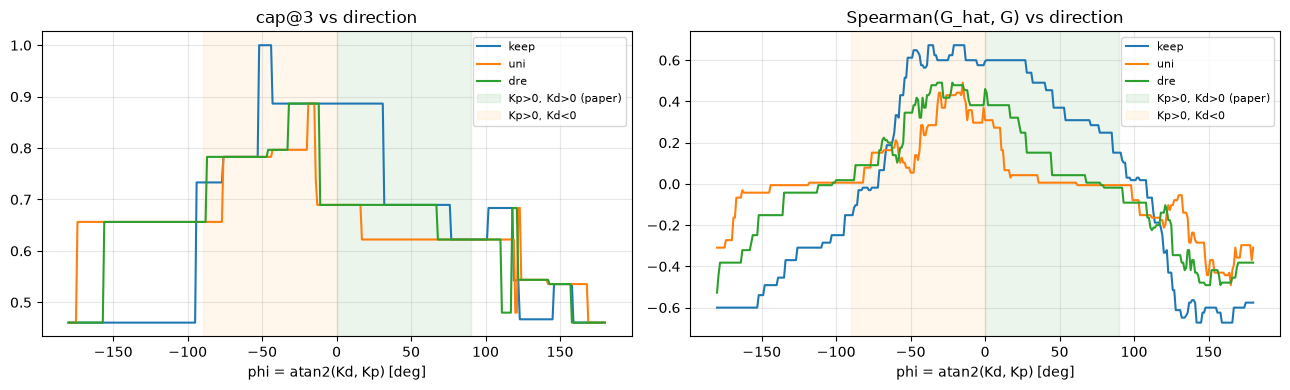

Spearman 최대 각도 [deg]: {'keep': -38.0, 'uni': -15.0, 'dre': -32.0} 
논문 Table 7 PACS Burst (Kp,Kd)=(1.0,0.1) -> phi = 5.7


In [7]:
phis = np.linspace(-np.pi, np.pi, 361)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
best = {}
for src in ['keep', 'uni', 'dre']:
    X = build_X(df[src]); y = X['G'].values
    caps = [capture(np.cos(p) * X['P'] + np.sin(p) * X['D'], y) for p in phis]
    sps = [stats.spearmanr(np.cos(p) * X['P'] + np.sin(p) * X['D'], y)[0] for p in phis]
    ax[0].plot(np.degrees(phis), caps, label=src); ax[1].plot(np.degrees(phis), sps, label=src)
    best[src] = np.degrees(phis[int(np.argmax(sps))])
for a, t in zip(ax, ['cap@3 vs direction', 'Spearman(G_hat, G) vs direction']):
    a.axvspan(0, 90, color='green', alpha=0.08, label='Kp>0, Kd>0 (paper)')
    a.axvspan(-90, 0, color='orange', alpha=0.08, label='Kp>0, Kd<0')
    a.set_xlabel('phi = atan2(Kd, Kp) [deg]'); a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Spearman 최대 각도 [deg]:', {k: round(v, 1) for k, v in best.items()},
      '\n논문 Table 7 PACS Burst (Kp,Kd)=(1.0,0.1) -> phi =', round(np.degrees(np.arctan2(0.1, 1.0)), 1))

**관찰**: Spearman이 최대가 되는 방향은 actual −38°, uniform −15°, DRE −32° — 모두 **$K_p>0, K_d<0$ 사분면**이고, 논문 Table 7의 PACS Burst 설정 $(1.0, 0.1)$ (+5.7°)과 반대쪽입니다. 즉 논문 상수를 그대로 가져오면 안 되고 **도메인(APIGraph)별 재추정이 필수**입니다. cap@3 곡선은 표본이 적어 계단형이며 넓은 각도 구간에서 같은 값을 가지므로, 방향 선택에는 Spearman 같은 연속 지표가 더 적합합니다.

**제안**: 이후 $K$ 탐색/학습은 (i) 각도 $\phi$를 순위 지표(Spearman, cap@k)로 고르고, (ii) 스케일은 예산 준수율(실제 update rate ≈ $\bar\lambda/\lambda$)로 맞추는 2단계로 분리하면 표본이 적어도 안정적입니다.

## §4. $K_p, K_d$의 시간 변화 — 라벨 지연을 지킨 expanding window

결정 시점 $t$에서 쓸 수 있는 학습 표본은 $G_s$의 라벨(=month $s+1$의 실제 loss)이 이미 도착한 것뿐입니다. 라벨 지연 $L$개월이면 $s+1+L \le t \Rightarrow s \le t-L-1$. 표본이 3개 이상일 때부터 추정합니다. 원본 노트북의 "월별 최적 K"(폭주하는 값)와 비교해 보면, 회귀 추정은 수렴 여부를 볼 수 있습니다.

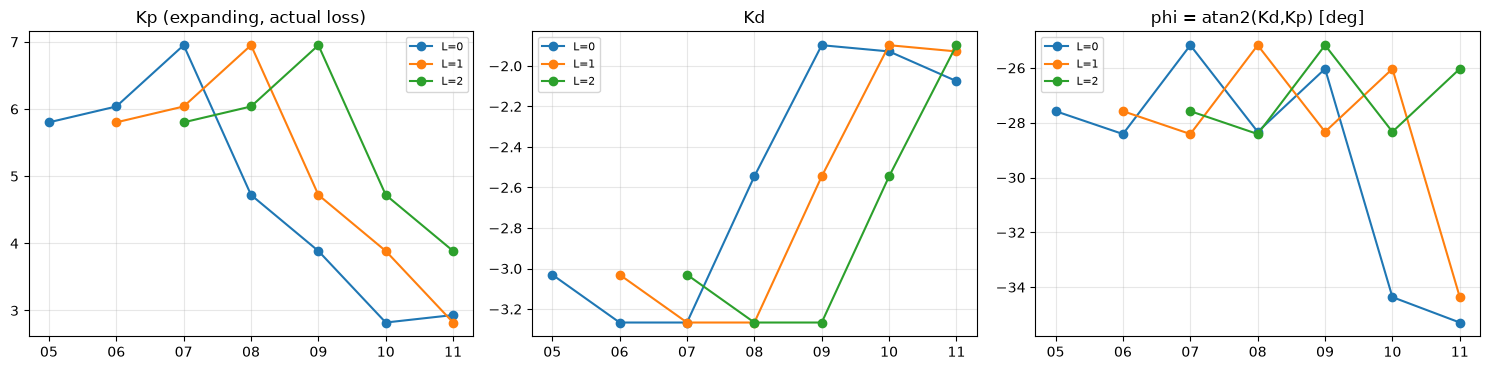

,n,Kp,Kd,phi_deg
t,,,,
2015-06,3,5.802,-3.030,-27.578
2015-07,4,6.038,-3.266,-28.412
2015-08,5,6.950,-3.266,-25.171
2015-09,6,4.720,-2.545,-28.331
2015-10,7,3.886,-1.898,-26.032
2015-11,8,2.821,-1.929,-34.363


In [8]:
def expanding_K(f, L=1, cols=('P', 'D'), intercept=False, min_n=3):
    X = build_X(f); months = list(df.index); out = []
    for t in X.index:
        ti = months.index(t)
        train = X[[months.index(s) <= ti - L - 1 for s in X.index]]
        if len(train) < min_n:
            continue
        k, _, _ = ls_fit(train[list(cols)].values, train['G'].values, intercept)
        out.append({'t': t, 'n': len(train), 'Kp': k[0], 'Kd': k[1], 'phi_deg': np.degrees(np.arctan2(k[1], k[0]))})
    return pd.DataFrame(out).set_index('t')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for L in [0, 1, 2]:
    e = expanding_K(df['keep'], L=L)
    ax[0].plot(e.index.str[5:], e['Kp'], 'o-', label=f'L={L}')
    ax[1].plot(e.index.str[5:], e['Kd'], 'o-', label=f'L={L}')
    ax[2].plot(e.index.str[5:], e['phi_deg'], 'o-', label=f'L={L}')
for a, t in zip(ax, ['Kp (expanding, actual loss)', 'Kd', 'phi = atan2(Kd,Kp) [deg]']):
    a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
expanding_K(df['keep'], L=1).round(3)

**관찰 포인트**
- 원본의 월별 역산값(−20 ~ +27로 폭주)과 달리, 회귀 추정은 $K_p$ 5.8→2.8, $K_d$ −3.0→−1.9로 **표본이 쌓이며 점차 작아지고**, 크기 변화에 비해 **방향 $\phi$는 −25° ~ −34°로 매우 안정적**입니다.
- 따라서 "방향은 고정, 스케일만 온라인 조정"하는 단순한 운영이 가능해 보입니다. 스케일이 줄어드는 것은 drift 구간(2015-10/11)의 큰 $P$가 학습에 들어오면서 생기는 효과로, $V$ 또는 예산 기반 큐가 흡수할 부분입니다.
- 라벨 지연 $L$이 커질수록 최근 drift 구간이 학습에서 늦게 반영되므로, 지연 자체가 $K$ 추정의 반응 속도를 결정합니다. → **라벨 지연 $L$을 실험 변수로 명시**하는 것을 제안합니다.

## §5. PAPE 오차 모델링

오차 $e_t = \hat f^{PAPE}_t - f_t$ (rate 기준). 질문:
1. 언제 틀리는가? → drift가 클 때(2015-10~12) 크게 **과소추정**
2. 무엇이 틀리는가? → FN vs FP 분해
3. 오차를 **라벨 없이** 예측할 수 있는가? → DRE 진단값(`dre_auc`, `ess_ratio`), seed 간 표준편차
4. 오차가 $P, D$ 특징으로 어떻게 전파되는가?

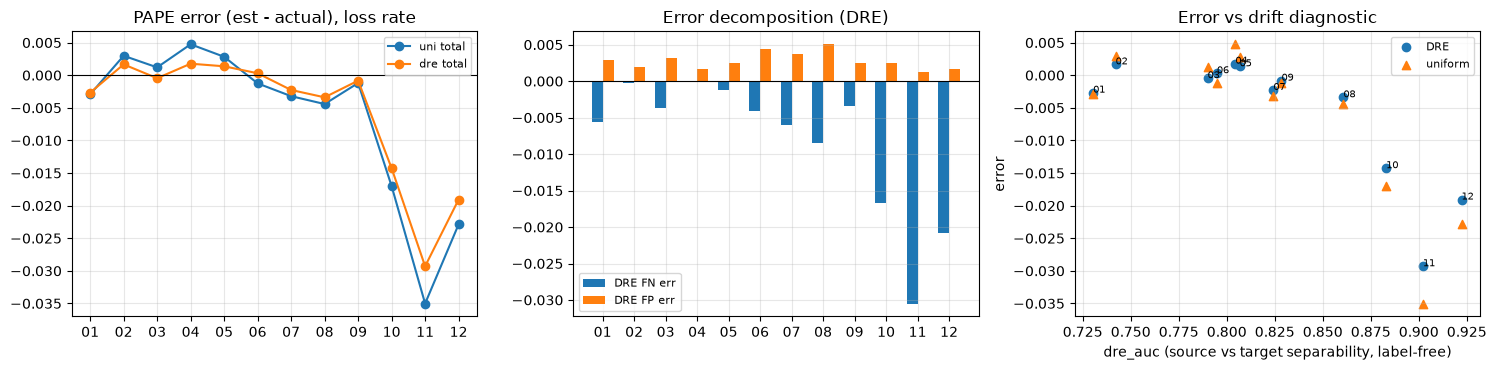

max_weight 값 분포: [20.] → 모든 달에서 clip 상한(20)에 도달


,uni_err,dre_err
dre_auc,-0.73,-0.71
ess_ratio,0.73,0.69
dre_sd,-0.77,-0.64
D_hat_dre,-0.22,-0.25
dre,-0.63,-0.66


In [9]:
for s in ['uni', 'dre']:
    df[f'{s}_err'] = df[s] - df['keep']
    df[f'{s}_fn_err'] = (df[f'{s}_fn'] - df['act_fn']) / df['n']
    df[f'{s}_fp_err'] = (df[f'{s}_fp'] - df['act_fp']) / df['n']

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
lbl = df.index.str[5:]
for s in ['uni', 'dre']:
    ax[0].plot(lbl, df[f'{s}_err'], 'o-', label=f'{s} total')
ax[0].axhline(0, color='k', lw=0.8); ax[0].set_title('PAPE error (est - actual), loss rate'); ax[0].legend(fontsize=8)
w = 0.35; xi = np.arange(len(df))
ax[1].bar(xi - w / 2, df['dre_fn_err'], w, label='DRE FN err'); ax[1].bar(xi + w / 2, df['dre_fp_err'], w, label='DRE FP err')
ax[1].set_xticks(xi); ax[1].set_xticklabels(lbl); ax[1].axhline(0, color='k', lw=0.8); ax[1].set_title('Error decomposition (DRE)'); ax[1].legend(fontsize=8)
ax[2].scatter(df['dre_auc'], df['dre_err'], label='DRE'); ax[2].scatter(df['dre_auc'], df['uni_err'], marker='^', label='uniform')
for m, r in df.iterrows():
    ax[2].annotate(m[5:], (r['dre_auc'], r['dre_err']), fontsize=7)
ax[2].set_xlabel('dre_auc (source vs target separability, label-free)'); ax[2].set_ylabel('error'); ax[2].set_title('Error vs drift diagnostic'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

cand = ['dre_auc', 'ess_ratio', 'dre_sd', 'D_hat_dre', 'dre']
df['D_hat_dre'] = df['dre'].diff()
corr = pd.DataFrame({e: [stats.spearmanr(df[c], df[e], nan_policy='omit')[0] for c in cand]
                     for e in ['uni_err', 'dre_err']}, index=cand)
print('max_weight 값 분포:', df['max_weight'].unique(), '→ 모든 달에서 clip 상한(20)에 도달')
corr.round(2)

**해석**
- 오차의 대부분은 **FN 과소추정**입니다 (FP 오차는 작고 오히려 과대추정). 즉 PAPE가 "새로 등장한 악성 앱을 놓치는 정도"를 따라가지 못합니다 — label shift / 새 family 출현에 importance weighting이 한계를 보이는 전형적인 형태입니다.
- `dre_auc`(source↔target 판별 AUC, 라벨 불필요)가 높을수록 과소추정이 커집니다 (Spearman ≈ −0.7). `ess_ratio`도 같은 방향. **drift 크기를 나타내는 라벨-프리 신호로 PAPE 오차를 예측/보정할 여지가 있습니다.**
- `max_weight`가 매달 clip 상한 20에 걸려 있습니다 → 강한 drift에서 weight clipping이 추정치를 source 쪽으로 끌어당기는 것으로 보입니다. **clip 상한 sweep(20/50/100/무제한) 실험을 PAPE 담당 쪽에 제안**할 만합니다.
- uniform은 seed 간 표준편차가 0이라 불확실성 정보가 없고, DRE는 drift 구간에서 sd가 커집니다 (2015-11: 16건). sd 자체도 신뢰도 신호로 쓸 수 있습니다.

In [10]:
# 오차가 RCCDA 특징으로 전파되는 정도
prop = []
Xa = build_X(df['keep'])
for s in ['uni', 'dre']:
    Xs = build_X(df[s])
    prop.append({'src': s,
                 'MAE(P_hat-P)': (Xs['P'] - Xa['P']).abs().mean(), 'corr(P_hat,P)': np.corrcoef(Xs['P'], Xa['P'])[0, 1],
                 'MAE(D_hat-D)': (Xs['D'] - Xa['D']).abs().mean(), 'corr(D_hat,D)': np.corrcoef(Xs['D'], Xa['D'])[0, 1],
                 'mean|P|': Xa['P'].abs().mean(), 'mean|D|': Xa['D'].abs().mean()})
pd.DataFrame(prop).round(4)

,src,MAE(P_hat-P),"corr(P_hat,P)",MAE(D_hat-D),"corr(D_hat,D)",mean|P|,mean|D|
0,uni,0.0082,0.6318,0.0057,0.7110,0.0148,0.0086
1,dre,0.0060,0.8254,0.0045,0.8032,0.0148,0.0086


$D$는 두 달 추정치의 차이라서 오차가 상쇄되기도 하지만, drift가 시작되는 달(2015-10)에는 PAPE가 loss *감소*를 보고해 $\hat D$의 부호가 뒤집힙니다. 오차 크기가 특징 크기($|P|, |D|$)와 같은 수준이라는 점이 §3에서 PAPE 기반 순위가 무너진 직접적 원인입니다.

## §6. 라벨 지연 하의 온라인 PAPE 보정

결정 시점 $t$, 라벨 지연 $L$개월이면 month $\le t-L$의 실제 loss는 이미 알고 있습니다. 이 "도착한 라벨"로 PAPE를 보정하는 방법들을 비교합니다 (모두 미래 정보 누수 없음).

| 방법 | 식 |
|---|---|
| raw | $\hat f_t$ |
| bias | $\hat f_t + \overline{(f_s-\hat f_s)}_{s\le t-L}$ |
| linear | $a + b\hat f_t$ ( $s\le t-L$로 적합) |
| last-residual | $\hat f_t + (f_{t-L} - \hat f_{t-L})$ — 가장 최근에 확인된 오차를 이어 붙임 |
| auc-reg | $\hat f_t + (\alpha + \beta\cdot \mathrm{dre\_auc}_t)$ — 오차를 라벨-프리 drift 신호로 회귀 |

평가: month 2015-05 ~ 2015-12 (보정용 표본이 3개 이상 쌓인 뒤) MAE.

In [11]:
def calibrate(src, L, method):
    est, act, auc = df[src].values, df['keep'].values, df['dre_auc'].values
    out = est.copy()
    for t in range(len(est)):
        lab = np.arange(0, t - L + 1)   # 라벨 도착한 month index
        if len(lab) < 3 or method == 'raw':
            continue
        r = act[lab] - est[lab]
        if method == 'bias':
            out[t] = est[t] + r.mean()
        elif method == 'linear':
            b, a = np.polyfit(est[lab], act[lab], 1); out[t] = a + b * est[t]
        elif method == 'last-residual':
            out[t] = est[t] + r[-1]
        elif method == 'auc-reg':
            b, a = np.polyfit(auc[lab], r, 1); out[t] = est[t] + a + b * auc[t]
    return pd.Series(out, index=df.index)

methods = ['raw', 'bias', 'linear', 'last-residual', 'auc-reg']
eval_mask = df.index >= '2015-05'
rows = []
for src in ['uni', 'dre']:
    for L in [1, 2, 3]:
        row = {'src': src, 'L': L}
        for m in methods:
            row[m] = (calibrate(src, L, m) - df['keep'])[eval_mask].abs().mean()
        rows.append(row)
res6 = pd.DataFrame(rows).set_index(['src', 'L'])
res6['best'] = res6[methods].idxmin(axis=1)
res6.round(4)

raw    bias  linear  last-residual  auc-reg           best
src L                                                               
uni 1  0.0110  0.0104  0.0104         0.0073   0.0074  last-residual
    2  0.0110  0.0113  0.0115         0.0089   0.0104  last-residual
    3  0.0110  0.0117  0.0112         0.0108   0.0126  last-residual
dre 1  0.0088  0.0079  0.0072         0.0058   0.0055        auc-reg
    2  0.0088  0.0086  0.0084         0.0070   0.0079  last-residual
    3  0.0088  0.0089  0.0081         0.0085   0.0092         linear

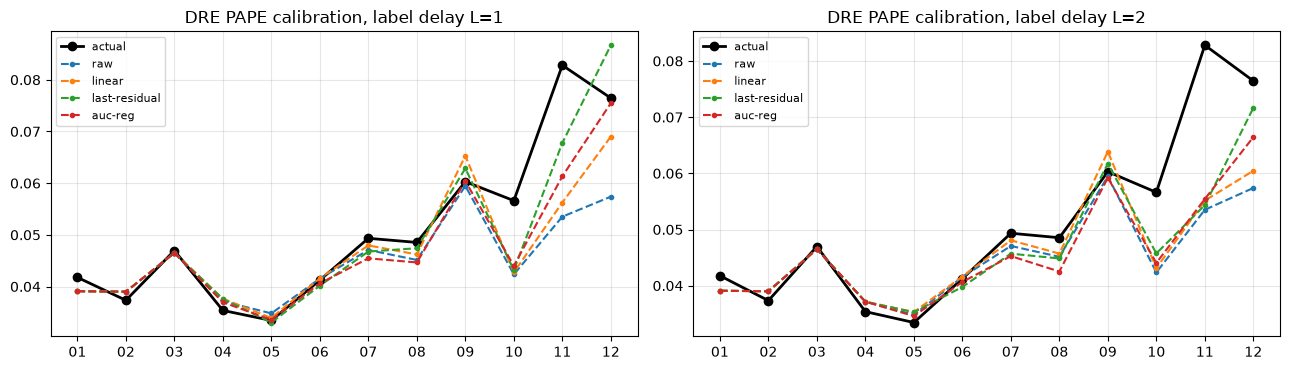

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, L in zip(ax, [1, 2]):
    a.plot(lbl, df['keep'], 'k-o', lw=2, label='actual')
    for m in ['raw', 'linear', 'last-residual', 'auc-reg']:
        a.plot(lbl, calibrate('dre', L, m), '--', marker='.', label=m)
    a.set_title(f'DRE PAPE calibration, label delay L={L}'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**해석**
- 지연 $L=1$에서는 **last-residual**(직전에 확인된 오차를 그대로 이어 붙이기)과 **auc-reg**가 raw 대비 MAE를 30–37% 줄입니다 (DRE 0.0088 → 0.0055/0.0058, uniform 0.0110 → 0.0073). drift 구간에서 PAPE 오차가 **자기상관(연속해서 과소추정)** 을 갖기 때문입니다.
- $L=2$에서는 last-residual만 유의미한 이득(약 20%)이 남고, $L=3$에서는 어떤 보정도 raw와 거의 같습니다 — 오래된 오차는 현재 drift를 대변하지 못합니다. auc-reg는 $L$이 길면 오히려 악화되는데, 적합에 쓰이는 라벨 구간에 drift 월이 아직 들어오지 않아 기울기를 못 배우기 때문입니다. **라벨 지연이 2개월 이상이면 "과거 오차로 보정"하는 전략 자체가 한계** → PAPE 추정기 개선(§9-5)이 필요합니다.
- linear/bias처럼 "전 기간 평균 오차"를 쓰는 방식은 drift 전 오차(≈0)에 끌려가 효과가 작습니다.

## §7. 라벨 지연 시나리오에서 보정 PAPE가 의사결정 품질을 얼마나 회복하는가

실제 운영에서 결정 시점 $t$의 loss 시계열은 **혼합 신호**입니다: month $\le t-L$은 실제 loss, 그 이후는 (보정된) PAPE. 이 혼합 시계열로 $P_t, D_t$를 계산하고, §3-1처럼 방향 $\phi$에 대한 Spearman/cap@3을 봅니다. $(K_p,K_d)$는 actual 기반 pooled fit(`P,D`) 방향과 Spearman 최대 방향 두 가지로 평가합니다.

In [13]:
def mixed_features(src, L, method):
    '''결정 시점별로 그 시점에 알 수 있는 정보만으로 P_t, D_t 계산'''
    cal = calibrate(src, L, method) if src != 'keep' else df['keep']
    months = list(df.index); rows = []
    for ti, t in enumerate(months):
        if ti == 0 or pd.isna(df['G'].iloc[ti]):
            continue
        f = np.array([df['keep'].iloc[s] if (s <= ti - L or src == 'keep') else cal.iloc[s] for s in range(ti + 1)])
        rows.append({'t': t, 'P': f[-1] - f.min(), 'D': f[-1] - f[-2], 'G': df['G'].iloc[ti]})
    return pd.DataFrame(rows).set_index('t')

k_act = res3.query("`f source`=='keep' and model=='P,D'")[['Kp/K', 'Kd']].values[0]
phi_fit = np.arctan2(k_act[1], k_act[0])
phi_best = np.radians(best['keep'])
rows = []
for L in [1, 2]:
    for src in ['uni', 'dre']:
        for m in ['raw', 'last-residual', 'auc-reg']:
            X = mixed_features(src, L, m)
            r = {'L': L, 'src': src, 'calib': m}
            for nm, ph in [('fit', phi_fit), ('best', phi_best)]:
                s = np.cos(ph) * X['P'] + np.sin(ph) * X['D']
                r[f'spearman[{nm}]'] = stats.spearmanr(s, X['G'])[0]
                r[f'cap@3[{nm}]'] = capture(s, X['G'])
            rows.append(r)
X0 = mixed_features('keep', 0, 'raw')
oracle = {'L': 0, 'src': 'actual', 'calib': '-'}
for nm, ph in [('fit', phi_fit), ('best', phi_best)]:
    s = np.cos(ph) * X0['P'] + np.sin(ph) * X0['D']
    oracle[f'spearman[{nm}]'] = stats.spearmanr(s, X0['G'])[0]; oracle[f'cap@3[{nm}]'] = capture(s, X0['G'])
res7 = pd.DataFrame([oracle] + rows)
res7.round(3)

,L,src,calib,spearman[fit],cap@3[fit],spearman[best],cap@3[best]
0,0,actual,-,0.564,0.886,0.673,0.886
1,1,uni,raw,0.576,0.886,0.612,0.886
2,1,uni,last-residual,0.515,0.886,0.515,0.886
3,1,uni,auc-reg,0.467,0.886,0.515,0.886
4,1,dre,raw,0.685,0.886,0.685,0.886
5,1,dre,last-residual,0.624,0.886,0.636,0.886
6,1,dre,auc-reg,0.576,0.886,0.673,0.886
7,2,uni,raw,0.261,0.797,0.273,0.797
8,2,uni,last-residual,0.358,0.886,0.358,0.886
9,2,uni,auc-reg,0.176,0.873,0.309,0.886


**읽는 법**: 첫 행(L=0, actual)이 라벨 지연이 없을 때의 기준입니다. `[best]` 열은 actual 데이터로 고른 방향이라 in-sample이며, `[fit]`과의 차이가 방향 선택의 민감도입니다.

**해석 (중요 — 기대와 다른 결과)**
- **L=1**: 혼합 구성에서는 현재 달 하나만 PAPE이므로 raw PAPE로도 cap@3이 actual과 같고(0.886), Spearman은 오히려 비슷하거나 높습니다(노이즈 수준 차이). **loss MAE를 줄인 보정(§6)이 순위 품질을 올리지는 않았고 오히려 Spearman이 약간 떨어졌습니다.** → "PAPE loss 오차 최소화"와 "재학습 의사결정 품질"은 같은 목표가 아닙니다. 보정 방법은 loss MAE가 아니라 의사결정 지표로 선택해야 합니다.
- **L=2**: raw PAPE에서 cap@3이 0.797로 떨어지고(Spearman 0.26/0.43), last-residual/auc-reg 보정이 cap@3을 0.886으로 **회복**시킵니다. 라벨 지연이 길수록 보정의 의사결정 가치가 생깁니다.
- cap@3은 10개 중 3개 선택이라 값이 몇 개로만 나뉘는 거친 지표입니다. 표본 확장 후 cap@k를 여러 k(예산)로 보고, 최종적으로는 §9-2의 RCCDA 시뮬레이션 누적 loss로 평가해야 합니다.

> 이 혼합 방식에서는 라벨이 도착한 과거 구간이 실제 loss로 대체되므로 PAPE는 최근 $L$개월에만 영향을 줍니다. $L$이 짧으면 원본 노트북처럼 "전 구간 PAPE"를 쓰는 것보다 훨씬 덜 비관적인 결과가 나옵니다 — **RCCDA+PAPE 평가 시 이 혼합 구성을 표준으로 쓰는 것을 제안**합니다.

## §8. 요약

| 구분 | 발견 | 근거 |
|---|---|---|
| 버그 | PAPE 행이 seed별 3중복 → 원본의 PAPE 기반 K, FN/FP 비교, 상관분석은 잘못된 달 매칭 | §1-1 |
| 버그 | `FP_uni`에 FN 대입, `min` off-by-one, keep/retrain 분해 부호 | §1-2 |
| 수식 | 월별 역산은 식별 불가 → pooled 회귀 + LOO로 추정해야 함 | §3 |
| 수식 | RCCDA 원형(절편 없음)은 actual loss로도 $R^2<0$; "재학습 기본 이득"을 설명할 항(절편 또는 재학습 도달 loss 기준의 P) 필요 | §2, §3 |
| 수식 | $K_d<0$ (bootstrap $P(K_d<0)\approx0.98$, 최적 방향 −15°~−38°) — 논문 상수(+5.7°)와 반대, 탐색 범위를 음수까지 확장 | §3, §3-1, 부록 |
| 튜닝 | 의사결정은 $K_d/K_p$ 방향에만 의존, 방향은 시간에 따라 안정적(−25°~−34°) → (방향, 스케일=V) 2단계 튜닝 | §3-1, §4 |
| PAPE | 오차는 drift 구간 FN 과소추정이 지배, `dre_auc`·seed sd와 강한 상관(|ρ|≈0.7), weight clip(20) 매달 포화 | §5 |
| 보정 | L=1에서 last-residual/auc-reg가 loss MAE 30–37% 감소, L≥3에서는 효과 없음 | §6 |
| 보정 | loss MAE 개선 ≠ 의사결정 개선: L=1에서는 보정 불필요, L=2에서 보정이 cap@3 회복 | §7 |

## §9. 추가로 진행하면 좋을 분석/실험 (우선순위 순)

1. **원본 노트북 버그 수정 후 재실행** — §1의 `agg`/merge 방식으로 교체. 현재 heatmap·K 그래프 결론은 폐기 권장.
2. **Loss matrix $L[s, m]$ 구축** (train_end $s$ × 평가월 $m$, 12×12 상삼각) — 지금은 "never retrain"과 "매월 retrain" 두 궤적만 있어 *임의 재학습 이력*의 loss를 알 수 없습니다. 이 행렬이 있으면 RCCDA(가상 큐 $Q$, $V$, 예산 $\bar\lambda/\lambda$ 포함)를 **정확히 시뮬레이션**하고 Uniform/Periodic baseline과 비교할 수 있습니다. 같은 이유로 PAPE도 각 train_end 모델에 대해 돌려야 운영과 동일한 $\hat f$가 나옵니다.
3. **표본 확장** — 2016–2018 test 구간(현재 미평가) 또는 주 단위 chunk. 결정 시점 10개로는 $K$ 2개 + 절편 추정이 한계.
4. **$\hat G$ 형태 확장 실험** — `P,D+c`, `Pref,D`, 그리고 PAPE 진단값(`dre_auc`, seed sd)을 $\hat G$의 추가 항으로 넣는 버전을 LOO/rolling-origin으로 비교.
5. **PAPE 쪽 개선 제안** — weight clip 상한 sweep, FN(양성 클래스) 전용 보정, `dre_auc` 임계값 기반 "PAPE 신뢰 불가" 플래그 → 플래그 시 RCCDA가 보수적으로(재학습 쪽으로) 판단.
6. **불확실성 정량화** — 10개 표본에 대한 bootstrap으로 $(K_p, K_d)$, $\phi$의 신뢰구간 제시 (발표 시 "Kd<0"이 노이즈인지 판단 근거).
7. **라벨 지연 $L$을 실험 축으로** 고정 — 모든 결과를 $L\in\{0,1,2,3\}$별로 보고.

In [14]:
# (부록) §9-6: (Kp, Kd) 방향의 bootstrap 신뢰구간 — 표본 10개의 불안정성 확인
# 주의: 월 단위 시계열을 iid로 리샘플링하므로 신뢰구간은 낙관적일 수 있음 (표본 확장 후 block bootstrap 권장)
rng = np.random.default_rng(0)
X = build_X(df['keep']); A = X[['P', 'D']].values; y = X['G'].values
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y), len(y))
    if np.linalg.matrix_rank(A[idx]) < 2:
        continue
    k = np.linalg.lstsq(A[idx], y[idx], rcond=None)[0]
    boot.append((k[0], k[1], np.degrees(np.arctan2(k[1], k[0]))))
boot = pd.DataFrame(boot, columns=['Kp', 'Kd', 'phi_deg'])
print('P(Kd < 0) =', round((boot['Kd'] < 0).mean(), 3))
boot.quantile([0.05, 0.5, 0.95]).round(3)

P(Kd < 0) = 0.98


,Kp,Kd,phi_deg
0.05,2.117,-3.499,-48.251
0.50,2.844,-2.283,-39.295
0.95,3.546,-0.823,-16.250
